# RiskLab

Uma nova empresa de concessão de crédito enfrenta o desafio de identificar clientes com maior probabilidade de inadimplência antes de liberar empréstimos. Sem um método estruturado de avaliação de risco, a empresa pode conceder crédito a clientes que não cumpram suas obrigações financeiras, aumentando as perdas. Assim, busca-se desenvolver um modelo preditivo capaz de estimar a probabilidade de um cliente apresentar inadimplência de 90 dias ou mais nos próximos 2 anos, utilizando seu histórico financeiro e comportamental para apoiar a análise de risco e tornar a concessão de crédito mais segura.

**Público alvo:** Analistas de concessão de crédito da empresa.


#### **Critérios de sucesso do projeto**

1-Qualidade dos dados: validar a integridade, os tipos, os valores ausentes e as regras de consistência da base, utilizando testes automatizados quando apropriado.

2-Desempenho do modelo: avaliar a capacidade de discriminação por meio da ROC-AUC, complementada por precision, recall e matriz de confusão.

3-Interpretabilidade: identificar e explicar os principais fatores associados às previsões, utilizando SHAP.

4-Utilidade para o negócio: traduzir os resultados técnicos em conclusões relevantes para a análise de risco de crédito.

5-Aplicação funcional: disponibilizar uma interface que permita consultar estimativas de risco e visualizar os resultados do modelo.



### Escolha do Dataset

**Dataset inicial:** Give Me Some Credit, Kaggle.

**Motivo:** O desenvolvimento de um modelo preditivo de risco de crédito exige uma variável-alvo que identifique a ocorrência de inadimplência, além de variáveis que permitam investigar características associadas a esse comportamento, o que está presente no dataset.

A análise será orientada pelo modelo dos 5 Cs do crédito (Caráter, Capacidade, Capital, Colateral e Condições), utilizado como referência para compreender as dimensões relevantes na avaliação do risco. Nesta primeira versão do RiskLab, serão exploradas as características de comportamento de pagamento e capacidade financeira disponíveis no dataset selecionado.

Em versões futuras, pretende-se utilizar o **Home Credit Default Risk**, ampliando a análise com outras informações dos clientes e explorando novas dimensões do risco de crédito, conforme a disponibilidade e a adequação das variáveis.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

df_training = pd.read_csv("cs_training.csv")
pd.options.display.float_format = '{:.2f}'.format

FileNotFoundError: [Errno 2] No such file or directory: 'cs_training.csv'

In [ ]:
#Conexao com SQL
conexao = sqlite3.connect("risklab.db")

df_training.to_sql(
    "cs_training",
    conexao,
    if_exists="replace",
    index=False
)

150000

## Visão Geral da Base

#### Significado de cada variável

**SeriousDlqin2yrs**: Inadimplência superior a 90 dias nos dois anos seguintes ao período de referência. Obs.: O conjunto de dados disponibilizado não fornece, na descrição consultada, datas individuais que permitam estabelecer o início e o fim exatos desse horizonte no calendário.

**RevolvingUtilizationOfUnsecuredLines**: Mede quanto do crédito disponível está sendo utilizado em relação ao limite que o cliente possui.

**Age**: Idade.

**NumberOfTime30-59DaysPastDueNotWorse**: Número de vezes que o cliente não pagou no tempo de 30-59 dias, mas sem evoluir para um tempo maior.

**DebtRatio**:	Índice de endividamento: pagamentos mensais de dívidas, pensão alimentícia e custos de vida dividido pela renda mensal bruta.

**MonthlyIncome**: Renda mensal.

**NumberOfOpenCreditLinesAndLoans**: Número de empréstimos em aberto (com pagamentos parcelados, como financiamento de veículo ou crédito imobiliário) e linhas de crédito (por exemplo, cartões de crédito)

**NumberOfTimes90DaysLate**:	Número de vezes que o cliente teve 90 dias ou mais de inadimplência.

**NumberRealEstateLoansOrLines**:	Número de empréstimos imobiliários e de crédito com garantia de imóvel (incluindo linhas de crédito com garantia de imóvel)

**NumberOfTime60-89DaysPastDueNotWorse**:	Número de vezes que o cliente não pagou no tempo de 60-89 dias, mas sem evoluir para um tempo maior. 

**NumberOfDependents**:	Número de dependentes.



In [ ]:
#Analisa os 5 primeiros clientes
consulta = """
SELECT * FROM cs_training LIMIT 5
"""

df = pd.read_sql_query(consulta, conexao)

display(df)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.77,45,2,0.80,9120.00,13,0,6,0,2.00
1,2,0,0.96,40,0,0.12,2600.00,4,0,0,0,1.00
2,3,0,0.66,38,1,0.09,3042.00,2,1,0,0,0.00
3,4,0,0.23,30,0,0.04,3300.00,5,0,0,0,0.00
4,5,0,0.91,49,1,0.02,63588.00,7,0,1,0,0.00


In [ ]:
#Analisa os 5 ultimos clientes
consulta = """
SELECT rowid, *
FROM cs_training
ORDER BY rowid DESC
LIMIT 5;
"""

df = pd.read_sql_query(consulta, conexao)
display(df)

,rowid,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,150000,150000,0,0.85,64,0,0.25,8158.00,8,0,2,0,0.00
1,149999,149999,0,0.00,30,0,0.00,5716.00,4,0,0,0,0.00
2,149998,149998,0,0.25,58,0,3870.00,NaN,18,0,1,0,0.00
3,149997,149997,0,0.30,44,0,0.72,5584.00,4,0,1,0,2.00
4,149996,149996,0,0.04,74,0,0.23,2100.00,4,0,1,0,0.00


In [ ]:
#Tamanho da base
df_training.shape

(150000, 12)

## Visualizando Resumo das Informações

In [ ]:
#Analise de valores faltantes
df_training.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

"MonthlyIncome" e "NumberOfDependents" com valores nulos

Analisando as variáveis com valores nulos

In [ ]:
#Analisa a quantidade de valores ausentes em cada coluna
consulta = """
SELECT SUM(CASE WHEN "MonthlyIncome" IS NULL THEN 1 ELSE 0 END) 
AS renda_ausente, 
SUM(CASE WHEN "NumberOfDependents" IS NULL THEN 1 ELSE 0 END) 
AS dependentes_ausentes 
FROM cs_training"""

df = pd.read_sql_query(consulta, conexao)

display(df)

,renda_ausente,dependentes_ausentes
0,29731,3924


In [ ]:
faltantes = df_training[["MonthlyIncome", "NumberOfDependents"]].isna()

print(pd.DataFrame({
    "ausentes": faltantes.sum(),
    "%": (faltantes.mean() * 100).round(2)
}))

                    ausentes     %
MonthlyIncome          29731 19.82
NumberOfDependents      3924  2.62


In [ ]:
#Comportamento das variaveis
df_training.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.00,150000.00,150000.00,150000.00,150000.00,150000.00,120269.00,150000.00,150000.00,150000.00,150000.00,146076.00
mean,75000.50,0.07,6.05,52.30,0.42,353.01,6670.22,8.45,0.27,1.02,0.24,0.76
std,43301.41,0.25,249.76,14.77,4.19,2037.82,14384.67,5.15,4.17,1.13,4.16,1.12
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,37500.75,0.00,0.03,41.00,0.00,0.18,3400.00,5.00,0.00,0.00,0.00,0.00
50%,75000.50,0.00,0.15,52.00,0.00,0.37,5400.00,8.00,0.00,1.00,0.00,0.00
75%,112500.25,0.00,0.56,63.00,0.00,0.87,8249.00,11.00,0.00,2.00,0.00,1.00
max,150000.00,1.00,50708.00,109.00,98.00,329664.00,3008750.00,58.00,98.00,54.00,98.00,20.00


In [ ]:
#Verificando valores únicos
df_training.nunique()

Unnamed: 0                              150000
SeriousDlqin2yrs                             2
RevolvingUtilizationOfUnsecuredLines    125728
age                                         86
NumberOfTime30-59DaysPastDueNotWorse        16
DebtRatio                               114194
MonthlyIncome                            13594
NumberOfOpenCreditLinesAndLoans             58
NumberOfTimes90DaysLate                     19
NumberRealEstateLoansOrLines                28
NumberOfTime60-89DaysPastDueNotWorse        13
NumberOfDependents                          13
dtype: int64

## Analisando as variáveis de forma individual

#### Variável alvo (SeriousDlqin2yrs)

In [ ]:
df_training.groupby(['SeriousDlqin2yrs']).size()

SeriousDlqin2yrs
0    139974
1     10026
dtype: int64

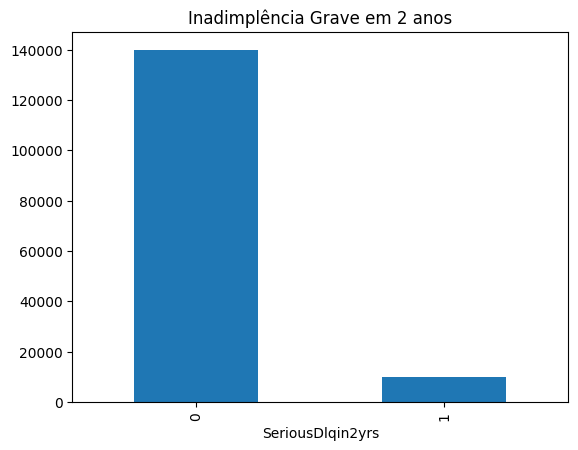

In [ ]:
df_training.SeriousDlqin2yrs.value_counts().plot(kind='bar', title='Inadimplência Grave em 2 anos')
plt.show()

Desbalanceamento na variável alvo!

In [ ]:
contagem = df_training["SeriousDlqin2yrs"].value_counts()
proporcao = df_training["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

print(pd.DataFrame({"clientes": contagem, "%": proporcao.round(2)}))

                  clientes     %
SeriousDlqin2yrs                
0                   139974 93.32
1                    10026  6.68


#### RevolvingUtilizationOfUnsecuredLines

In [ ]:
#Analise da distribuicao da variavel RevolvingUtilizationOfUnsecuredLines
consulta = """
SELECT RevolvingUtilizationOfUnsecuredLines
FROM cs_training
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["RevolvingUtilizationOfUnsecuredLines"],
    bins=np.linspace(0, df_revolving["RevolvingUtilizationOfUnsecuredLines"].max(), 20),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

consulta = """
SELECT
    SUM(CASE
        WHEN RevolvingUtilizationOfUnsecuredLines BETWEEN 0 AND 1 THEN 1
        ELSE 0
    END) AS TaxaRevolvingEntre0e1,

    SUM(CASE
        WHEN RevolvingUtilizationOfUnsecuredLines > 1 AND RevolvingUtilizationOfUnsecuredLines <= 2 THEN 1
        ELSE 0
    END) AS TaxaRevolving1e2,

    SUM(CASE
            WHEN RevolvingUtilizationOfUnsecuredLines > 2 AND RevolvingUtilizationOfUnsecuredLines <= 3 THEN 1
            ELSE 0
    END) AS TaxaRevolving2e3,

    SUM(CASE
                WHEN RevolvingUtilizationOfUnsecuredLines > 3 AND RevolvingUtilizationOfUnsecuredLines <= 4 THEN 1
                ELSE 0
    END) AS TaxaRevolving3e4,

    SUM(CASE               
                    WHEN RevolvingUtilizationOfUnsecuredLines > 10 AND RevolvingUtilizationOfUnsecuredLines <= 50708 THEN 1
                    ELSE 0
        END) AS TaxaRevolving10e50708

FROM cs_training"""

df = pd.read_sql_query(consulta, conexao)

display(df)


,Faixa de valores,Quantidade
0,"(-0.001, 2668.842]",149906
1,"(2668.842, 5337.684]",50
2,"(5337.684, 8006.526]",20
3,"(8006.526, 10675.368]",10
4,"(10675.368, 13344.211]",4
5,"(13344.211, 16013.053]",3
6,"(16013.053, 18681.895]",2
7,"(18681.895, 21350.737]",1
8,"(21350.737, 24019.579]",2
9,"(24019.579, 26688.421]",0


,TaxaRevolvingEntre0e1,TaxaRevolving1e2,TaxaRevolving2e3,TaxaRevolving3e4,TaxaRevolving10e50708
0,146679,2950,79,28,241


In [ ]:
col = "RevolvingUtilizationOfUnsecuredLines"

taxa = (df_training[col] <= 1).mean() * 100
print(f"Porcentagem dos clientes com revolving de até 1: {taxa:.2f}%")

Porcentagem dos clientes com revolving de até 1: 97.79%


In [ ]:
col = "RevolvingUtilizationOfUnsecuredLines"

taxa = (df_training[col] <= 2).mean() * 100
print(f"Porcentagem dos clientes com revolving de até 2: {taxa:.2f}%")

Porcentagem dos clientes com revolving de até 2: 99.75%


In [ ]:
df_revolving["RevolvingUtilizationOfUnsecuredLines"].nlargest(20)

85489    50708.00
31414    29110.00
16956    22198.00
149160   22000.00
149279   20514.00
117315   18300.00
21978    17441.00
124533   13930.00
72592    13498.00
71705    13400.00
125718   12369.00
58852    11843.00
83052    11553.00
76726    10821.00
13669    10209.00
123071   10151.00
50695     9684.00
8199      9340.00
60021     9193.00
99651     8831.00
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

#### Age

In [ ]:
#Analise da distribuicao da variavel age
consulta = """
SELECT age
FROM cs_training
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["age"],
    bins=np.linspace(0, df_revolving["age"].max(), 21),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

tabela["Faixa de valores"] = tabela["Faixa de valores"].apply(
    lambda x: f"({x.left:.2f}, {x.right:.2f}]"
)

display(tabela)

,Faixa de valores,Quantidade
0,"(-0.00, 5.45]",1
1,"(5.45, 10.90]",0
2,"(10.90, 16.35]",0
3,"(16.35, 21.80]",183
4,"(21.80, 27.25]",5375
5,"(27.25, 32.70]",9287
6,"(32.70, 38.15]",14171
7,"(38.15, 43.60]",15492
8,"(43.60, 49.05]",21872
9,"(49.05, 54.50]",18198


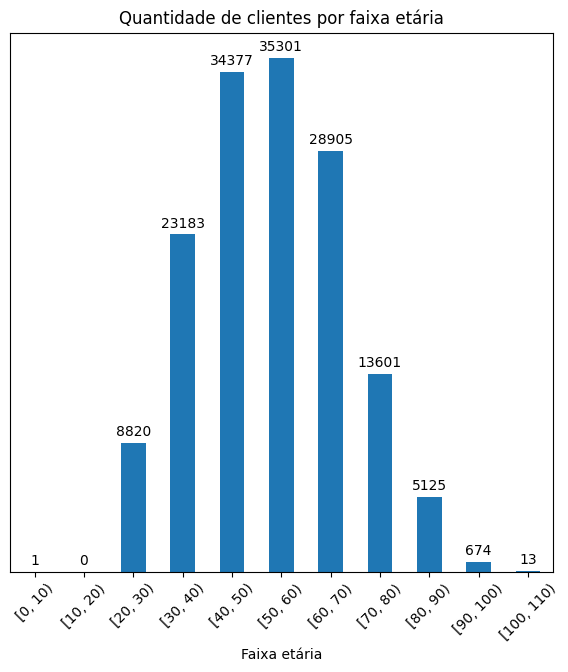

In [ ]:
consulta = """
SELECT age
FROM cs_training
"""

df_idades = pd.read_sql_query(consulta, conexao)

# Criar faixas etárias de 10 anos
faixas = pd.cut(
    df_idades["age"],
    bins=range(0, 111, 10),
    right=False
)

# Contar clientes em cada faixa
quantidades = faixas.value_counts(sort=False)

# Criar o gráfico
ax = quantidades.plot(kind="bar", figsize=(7, 7))

# Mostrar a quantidade exata em cada barra
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Quantidade de clientes por faixa etária")
plt.xlabel("Faixa etária")
plt.xticks(rotation=45)
ax.set_yticks([])
plt.show()

#### NumberOfTime30-59DaysPastDueNotWorse

In [ ]:
#Analisa a distribuicao de valores em NumberOfTime30-59DaysPastDueNotWorse	

consulta = """
SELECT "NumberOfTime30-59DaysPastDueNotWorse"		
FROM cs_training
"""

df_number = pd.read_sql_query(consulta, conexao)

df_number["Faixa"] = pd.cut(
    df_number["NumberOfTime30-59DaysPastDueNotWorse"],
    bins=10
)

tabela = df_number["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

,Faixa de valores,Quantidade
0,"(-0.098, 9.8]",149723
1,"(9.8, 19.6]",8
2,"(19.6, 29.4]",0
3,"(29.4, 39.2]",0
4,"(39.2, 49.0]",0
5,"(49.0, 58.8]",0
6,"(58.8, 68.6]",0
7,"(68.6, 78.4]",0
8,"(78.4, 88.2]",0
9,"(88.2, 98.0]",269


Por que não há valores entre 20 e 89, mas 269 valores entre 89 e 98? Algo a ser analisado.

In [ ]:
df_training["NumberOfTime30-59DaysPastDueNotWorse"].value_counts().sort_index().tail(15)

NumberOfTime30-59DaysPastDueNotWorse
1     16033
2      4598
3      1754
4       747
5       342
6       140
7        54
8        25
9        12
10        4
11        1
12        2
13        1
96        5
98      264
Name: count, dtype: int64

Seria 98 algum tipo de código? Analisaremos o comportamento com o default futuramente.

#### DebtRatio

In [ ]:
#Analisa a distribuicao de valores em DebtRatio

consulta = """
SELECT DebtRatio
FROM cs_training
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["DebtRatio"],
    bins=160
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

#Quantidade de pessoas com DebtRatio entre 0 e 1
consulta = """
SELECT
    SUM(CASE
        WHEN DebtRatio BETWEEN 0 AND 1 THEN 1
        ELSE 0
    END) AS DebtRatioEntre0e1,

    SUM(CASE
        WHEN DebtRatio > 1 AND DebtRatio <= 2 THEN 1
        ELSE 0
    END) AS DebtRatioEntre1e2,

    SUM(CASE
            WHEN DebtRatio > 2 AND DebtRatio <= 3 THEN 1
            ELSE 0
    END) AS DebtRatioEntre2e3,

    SUM(CASE
                WHEN DebtRatio > 3 AND DebtRatio <= 4 THEN 1
                ELSE 0
    END) AS DebtRatioEntre3e4

FROM cs_training"""

df = pd.read_sql_query(consulta, conexao)

display(df)


,Faixa de valores,Quantidade
0,"(-329.664, 2060.4]",140387
1,"(2060.4, 4120.8]",7089
2,"(4120.8, 6181.2]",1770
3,"(6181.2, 8241.6]",448
4,"(8241.6, 10302.0]",143
...,...,...
155,"(319362.0, 321422.4]",0
156,"(321422.4, 323482.8]",0
157,"(323482.8, 325543.2]",0
158,"(325543.2, 327603.6]",1


,DebtRatioEntre0e1,DebtRatioEntre1e2,DebtRatioEntre2e3,DebtRatioEntre3e4
0,114863,4092,762,392


In [ ]:
df_training[["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

,RevolvingUtilizationOfUnsecuredLines,DebtRatio
0.90,0.98,1267.00
0.95,1.00,2449.00
0.99,1.09,4979.04
1.00,1571.01,10613.07
1.00,10151.01,40362.00


Note que a partir de 0.99 o valor de Revolving explode.

DebtRatio teria alguma relação com os valores ausentes de MonthlyIncome?

In [ ]:
df_training.assign(renda_ausente=df_training["MonthlyIncome"].isna().astype(int)) \
    .groupby("renda_ausente")["DebtRatio"] \
    .describe(percentiles=[0.5, 0.9, 0.99])

,count,mean,std,min,50%,90%,99%,max
renda_ausente,,,,,,,,
0,120269.00,26.60,424.45,0.00,0.30,0.76,661.82,61106.50
1,29731.00,1673.40,4248.37,0.00,1159.00,3785.00,8084.50,329664.00


In [ ]:
d = df_training.copy()
d["renda_ausente"] = d["MonthlyIncome"].isna()

corte = d["DebtRatio"].quantile(0.90)
top = d[d["DebtRatio"] > corte]

print("Corte (p90):", round(corte, 2))
print("Média do top 10%:", round(top["DebtRatio"].mean(), 2))
print("Mediana do top 10%:", round(top["DebtRatio"].median(), 2))
print("% com renda ausente no top 10%:", round(top["renda_ausente"].mean() * 100, 1))
print("% com renda ausente na base toda:", round(d["renda_ausente"].mean() * 100, 1))

Corte (p90): 1267.0
Média do top 10%: 3117.42
Mediana do top 10%: 2449.0
% com renda ausente no top 10%: 94.3
% com renda ausente na base toda: 19.8


94.3% ausente para 19.8 é uma porcentagem expressiva.

A escala bate?

In [ ]:
g0 = d[~d["renda_ausente"]]
divida_implicita = g0["DebtRatio"] * g0["MonthlyIncome"]
g1 = d.loc[d["renda_ausente"], "DebtRatio"]

comparacao = pd.DataFrame({
    "Renda informada: dívida implícita (DebtRatio × renda)": divida_implicita.describe(percentiles=[.5, .9, .99]),
    "Renda ausente: DebtRatio bruto": g1.describe(percentiles=[.5, .9, .99]),
})
print(comparacao.round(2))

       Renda informada: dívida implícita (DebtRatio × renda)  \
count                                          120269.00       
mean                                             2117.75       
std                                              4196.60       
min                                                 0.00       
50%                                              1619.79       
90%                                              4375.46       
99%                                              9398.30       
max                                            478450.56       

       Renda ausente: DebtRatio bruto  
count                        29731.00  
mean                          1673.40  
std                           4248.37  
min                              0.00  
50%                           1159.00  
90%                           3785.00  
99%                           8084.50  
max                         329664.00  


In [ ]:
d = df_training.copy()

g1 = d[d["MonthlyIncome"].isna()]["DebtRatio"]
g0 = d[d["MonthlyIncome"].notna()]["DebtRatio"]

print("Renda ausente com DebtRatio <= 1:",
      round((g1 <= 1).mean() * 100, 1), "%")

print("Renda informada com DebtRatio > 1:",
      round((g0 > 1).mean() * 100, 1), "%")

print("Renda informada com DebtRatio > 100:",
      round((g0 > 100).mean() * 100, 1), "%")

Renda ausente com DebtRatio <= 1: 6.1 %
Renda informada com DebtRatio > 1: 6.0 %
Renda informada com DebtRatio > 100: 1.4 %


Achado: o DebtRatio não é uma razão para clientes sem renda informada

O percentil 90 do DebtRatio já é valor, incompatível com uma razão dívida/renda. Ao separar os clientes pela presença de renda, o comportamento muda de forma clara:

**Renda informada:** mediana de 0,30, com 90% dos clientes abaixo de 0,77. Comporta-se como uma razão.
**Renda ausente:** mediana de 1.149, com 90% abaixo de 3.756. Os valores estão na casa de milhares.

A interpretação mais plausível é que, quando a renda está ausente, a coluna guarda o valor absoluto da dívida em vez da razão. Os valores elevados, portanto, **não são outliers no sentido usual**: são duas grandezas diferentes na mesma coluna. Por isso, limitar a variável por percentil não resolveria o problema e apenas o esconderia.

Mesmo entre os clientes com renda informada, o percentil 99 é 640, o que ainda é incompatível com uma razão. Isso sugere renda declarada muito baixa em parte dos casos, o que deve ser investigado na etapa de tratamento.

#### MonthlyIncome

In [ ]:
#Analisa a distribuicao de valores em MonthlyIncome

consulta = """
SELECT MonthlyIncome
FROM cs_training
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["MonthlyIncome"],
    bins=np.linspace(0, df_revolving["MonthlyIncome"].max(), 10),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

#Analisa a distribuicao dos valores até 334305.556
consulta = """
SELECT MonthlyIncome
FROM cs_training
WHERE MonthlyIncome <= 334305.556
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["MonthlyIncome"],
    bins=np.linspace(0, df_revolving["MonthlyIncome"].max(), 10),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

#Analisa a distribuicao dos valores até 36000.0
consulta = """
SELECT MonthlyIncome
FROM cs_training
WHERE MonthlyIncome <= 36000.0
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["MonthlyIncome"],
    bins=np.linspace(0, df_revolving["MonthlyIncome"].max(), 10),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

#Analisa a distribuicao dos valores até 40398
consulta = """
SELECT MonthlyIncome
FROM cs_training
WHERE MonthlyIncome <= 4000
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["MonthlyIncome"],
    bins=np.linspace(0, df_revolving["MonthlyIncome"].max(), 10),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

,Faixa de valores,Quantidade
0,"(-0.001, 334305.556]",120254
1,"(334305.556, 668611.111]",7
2,"(668611.111, 1002916.667]",4
3,"(1002916.667, 1337222.222]",1
4,"(1337222.222, 1671527.778]",1
5,"(1671527.778, 2005833.333]",1
6,"(2005833.333, 2340138.889]",0
7,"(2340138.889, 2674444.444]",0
8,"(2674444.444, 3008750.0]",1


,Faixa de valores,Quantidade
0,"(-0.001, 36000.0]",119710
1,"(36000.0, 72000.0]",408
2,"(72000.0, 108000.0]",87
3,"(108000.0, 144000.0]",24
4,"(144000.0, 180000.0]",10
5,"(180000.0, 216000.0]",3
6,"(216000.0, 252000.0]",8
7,"(252000.0, 288000.0]",2
8,"(288000.0, 324000.0]",2


,Faixa de valores,Quantidade
0,"(-0.001, 4000.0]",40398
1,"(4000.0, 8000.0]",48420
2,"(8000.0, 12000.0]",20709
3,"(12000.0, 16000.0]",6390
4,"(16000.0, 20000.0]",2249
5,"(20000.0, 24000.0]",736
6,"(24000.0, 28000.0]",419
7,"(28000.0, 32000.0]",242
8,"(32000.0, 36000.0]",147


,Faixa de valores,Quantidade
0,"(-0.001, 444.444]",2655
1,"(444.444, 888.889]",1416
2,"(888.889, 1333.333]",2230
3,"(1333.333, 1777.778]",3022
4,"(1777.778, 2222.222]",4633
5,"(2222.222, 2666.667]",5771
6,"(2666.667, 3111.111]",6490
7,"(3111.111, 3555.556]",6624
8,"(3555.556, 4000.0]",7557


#### NumberOfOpenCreditLinesAndLoans

In [ ]:
#Analisa a distribuicao de valores em NumberOfOpenCreditLinesAndLoans
consulta = """
SELECT NumberOfOpenCreditLinesAndLoans
FROM cs_training
"""

df_revolving = pd.read_sql_query(consulta, conexao)

df_revolving["Faixa"] = pd.cut(
    df_revolving["NumberOfOpenCreditLinesAndLoans"],
    bins=np.linspace(0, df_revolving["NumberOfOpenCreditLinesAndLoans"].max(), 10),
    include_lowest=True
)

tabela = df_revolving["Faixa"].value_counts(sort=False).reset_index()

tabela.columns = ["Faixa de valores", "Quantidade"]

display(tabela)

,Faixa de valores,Quantidade
0,"(-0.001, 6.444]",60204
1,"(6.444, 12.889]",62112
2,"(12.889, 19.333]",22535
3,"(19.333, 25.778]",4010
4,"(25.778, 32.222]",911
5,"(32.222, 38.667]",147
6,"(38.667, 45.111]",49
7,"(45.111, 51.556]",19
8,"(51.556, 58.0]",13


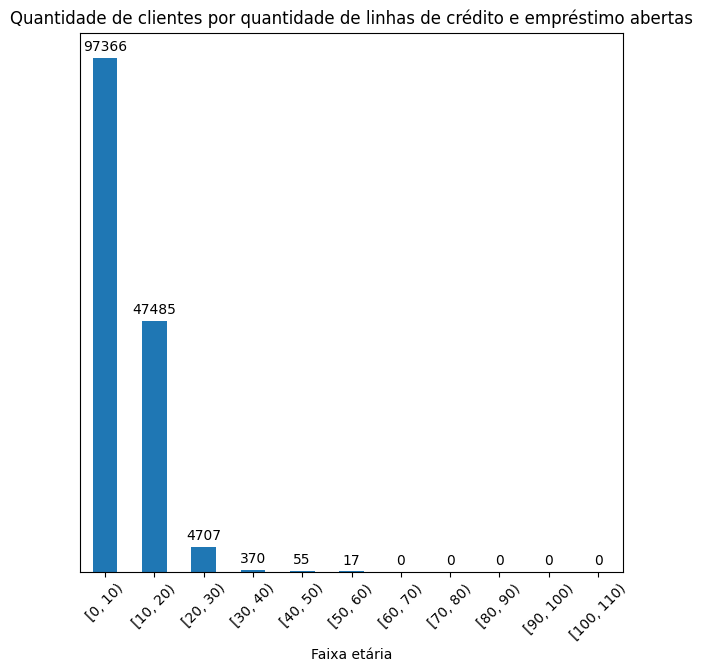

In [ ]:
consulta = """
SELECT NumberOfOpenCreditLinesAndLoans
FROM cs_training
"""

df_idades = pd.read_sql_query(consulta, conexao)

faixas = pd.cut(
    df_idades["NumberOfOpenCreditLinesAndLoans"],
    bins=range(0, 111, 10),
    right=False
)

quantidades = faixas.value_counts(sort=False)

# Criar o gráfico
ax = quantidades.plot(kind="bar", figsize=(7, 7))

# Mostrar a quantidade exata em cada barra
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Quantidade de clientes por quantidade de linhas de crédito e empréstimo abertas")
plt.xlabel("Faixa etária")
plt.xticks(rotation=45)
ax.set_yticks([])
plt.show()

#### NumberOfTimes90DaysLate

In [ ]:
df_training.groupby(['NumberOfTimes90DaysLate']).size()

NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
dtype: int64

#### NumberRealEstateLoansOrLines

In [ ]:
df_training.groupby(['NumberRealEstateLoansOrLines']).size()

NumberRealEstateLoansOrLines
0     56188
1     52338
2     31522
3      6300
4      2170
5       689
6       320
7       171
8        93
9        78
10       37
11       23
12       18
13       15
14        7
15        7
16        4
17        4
18        2
19        2
20        2
21        1
23        2
25        3
26        1
29        1
32        1
54        1
dtype: int64

#### NumberOfTime60-89DaysPastDueNotWorse

In [ ]:
df_training.groupby(['NumberOfTime60-89DaysPastDueNotWorse']).size()

NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
4        105
5         34
6         16
7          9
8          2
9          1
11         1
96         5
98       264
dtype: int64

#### NumberOfDependents

In [ ]:
df_training.groupby(['NumberOfDependents']).size()

NumberOfDependents
0.00     86902
1.00     26316
2.00     19522
3.00      9483
4.00      2862
5.00       746
6.00       158
7.00        51
8.00        24
9.00         5
10.00        5
13.00        1
20.00        1
dtype: int64

## Relação das Variáveis Com o Default

#### RevolvingUtilizationOfUnsecuredLines

In [ ]:
# Criar faixas de utilização de crédito
bins = [0, 0.25, 0.5, 0.75, 1, 1.5, 1.8, 2, 3, 4, 5, 10, 20, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_revolving = df_training[
    ["RevolvingUtilizationOfUnsecuredLines", "SeriousDlqin2yrs"]
].copy()

df_revolving["Faixa"] = pd.cut(
    df_revolving["RevolvingUtilizationOfUnsecuredLines"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_revolving.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(-0.001, 0.25]",87657,1873,2.14
1,"(0.25, 0.5]",21055,1114,5.29
2,"(0.5, 0.75]",13764,1394,10.13
3,"(0.75, 1.0]",24203,4408,18.21
4,"(1.0, 1.5]",2721,1081,39.73
5,"(1.5, 1.8]",160,70,43.75
6,"(1.8, 2.0]",69,32,46.38
7,"(2.0, 3.0]",79,25,31.65
8,"(3.0, 4.0]",28,6,21.43
9,"(4.0, 5.0]",10,3,30.00


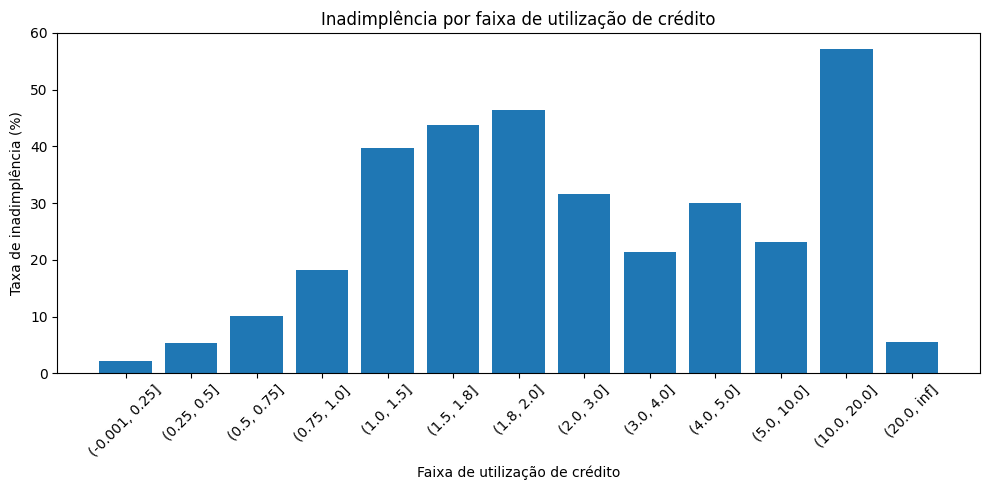

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela["Faixa"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Faixa de utilização de crédito")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Inadimplência por faixa de utilização de crédito")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Maior taxa de inadimplência para quem tem revolving entre 1 e 2.

Por que a taxa de inadimplência decresce a partir do revolving > 2?

In [ ]:
df_revolving.loc[
    df_revolving["RevolvingUtilizationOfUnsecuredLines"] > 2,
    [
        "RevolvingUtilizationOfUnsecuredLines",
        "SeriousDlqin2yrs"
    ]
].sort_values(
    "RevolvingUtilizationOfUnsecuredLines",
    ascending=False
).head(50)

,RevolvingUtilizationOfUnsecuredLines,SeriousDlqin2yrs
85489,50708.00,0
31414,29110.00,0
16956,22198.00,0
149160,22000.00,0
149279,20514.00,0
117315,18300.00,0
21978,17441.00,0
124533,13930.00,0
72592,13498.00,0
71705,13400.00,0


Apenas 2 dos 50 maiores valores em Revolving entraram em inadimplência.

In [ ]:
#Analisa a inadimplencia de forma mais minuciosa no Relvoving > 20
# Criar faixas de utilização de crédito
bins = [20, 30, 50, 100, 1000, 10000, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_revolving = df_training[
    ["RevolvingUtilizationOfUnsecuredLines", "SeriousDlqin2yrs"]
].copy()

df_revolving["Faixa"] = pd.cut(
    df_revolving["RevolvingUtilizationOfUnsecuredLines"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_revolving.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(19.999, 30.0]",1,1,100.00
1,"(30.0, 50.0]",3,0,0.00
2,"(50.0, 100.0]",7,1,14.29
3,"(100.0, 1000.0]",51,1,1.96
4,"(1000.0, 10000.0]",156,10,6.41
5,"(10000.0, inf]",16,0,0.00


In [ ]:
col = "RevolvingUtilizationOfUnsecuredLines"

taxa = (df_training[col] > 100).mean() * 100
print(f"Taxa de clientes com Revolving acima de 100: {taxa:.2f}%")

Taxa de clientes com Revolving acima de 100: 0.15%


In [ ]:
#Valores acima de 2 que levaram à inadimplência
valores = df_revolving.loc[
    (df_revolving["SeriousDlqin2yrs"] == 1) &
    (df_revolving["RevolvingUtilizationOfUnsecuredLines"] > 2),
    "RevolvingUtilizationOfUnsecuredLines"
].sort_values(ascending=True).reset_index(drop=True)

display(valores.to_frame())

,RevolvingUtilizationOfUnsecuredLines
0,2.01
1,2.01
2,2.02
3,2.02
4,2.04
5,2.05
6,2.08
7,2.08
8,2.11
9,2.14


A análise indica que a faixa de utilização de crédito entre 1 e 2 apresenta as maiores taxas de inadimplência, com destaque para o intervalo entre 1,8 e 2, que apresentou uma taxa de 46,38%.

Em contrapartida, valores extremos de revolving não estiveram necessariamente associados à inadimplência, apresentando taxas distintas conforme a faixa analisada.

Dessa forma, é necessário investigar o perfil dos clientes com valores extremos de revolving para compreender a origem desses registros e determinar se são valores válidos ou possíveis outliers que demandam tratamento.

In [ ]:
colunas = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "SeriousDlqin2yrs"
]

extremos = df_training.loc[
    df_training["RevolvingUtilizationOfUnsecuredLines"] > 100,
    colunas
].sort_values(
    by="RevolvingUtilizationOfUnsecuredLines",
    ascending=False
)

display(extremos)

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,SeriousDlqin2yrs
85489,50708.00,55,0,0.22,38000.00,7,0
31414,29110.00,58,0,0.40,10000.00,7,0
16956,22198.00,38,0,2312.00,NaN,5,0
149160,22000.00,38,0,1.08,3973.00,7,0
149279,20514.00,42,0,0.06,9902.00,1,0
...,...,...,...,...,...,...,...
22483,206.00,25,1,0.09,5250.00,4,0
23210,143.00,58,0,0.00,5000.00,3,0
99894,135.00,67,1,1761.00,NaN,8,0
98758,114.00,82,0,4.00,NaN,4,0


Baixa densidade de informações para concluir algo. Utilizemos o método Wilson para melhor acurácia.

In [ ]:
from statsmodels.stats.proportion import proportion_confint

grupos = [
    ("2 a 10", 37, 180),
    ("10 a 100", 6, 18),
    ("Acima de 1000", 10, 172)
]

for nome, inadimplentes, total in grupos:
    inferior, superior = proportion_confint(
        inadimplentes,
        total,
        alpha=0.05,
        method="wilson"
    )

    print(
        f"{nome}: "
        f"{inadimplentes / total:.2%} "
        f"(IC 95%: {inferior:.2%} a {superior:.2%})"
    )

2 a 10: 20.56% (IC 95%: 15.30% a 27.04%)
10 a 100: 33.33% (IC 95%: 16.28% a 56.25%)
Acima de 1000: 5.81% (IC 95%: 3.19% a 10.37%)


Grande discrepância de valores entre as faixas analisadas devido a baixa quantidade de informações.

In [ ]:
# Seleciona os clientes com revolving acima de 1000
df_extremos = df_training[
    df_training["RevolvingUtilizationOfUnsecuredLines"] > 1000
]

# Calcula a mediana de todas as variáveis numéricas desse grupo
medianas = df_extremos.median(numeric_only=True)

display(medianas)

Unnamed: 0                             83547.00
SeriousDlqin2yrs                           0.00
RevolvingUtilizationOfUnsecuredLines    3099.50
age                                       47.00
NumberOfTime30-59DaysPastDueNotWorse       0.00
DebtRatio                                  0.38
MonthlyIncome                           7041.50
NumberOfOpenCreditLinesAndLoans            5.00
NumberOfTimes90DaysLate                    0.00
NumberRealEstateLoansOrLines               1.00
NumberOfTime60-89DaysPastDueNotWorse       0.00
NumberOfDependents                         0.00
dtype: float64

In [ ]:
coluna_revolving = "RevolvingUtilizationOfUnsecuredLines"

df_extremos = df_training[
    df_training[coluna_revolving] > 1000
]

colunas_atraso = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for coluna in colunas_atraso:
    print(f"\n{coluna}")
    print(df_extremos[coluna].value_counts().sort_index())


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0    154
1     10
2      8
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0    167
1      5
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0    168
1      3
3      1
Name: count, dtype: int64


Nota-se que o grupo com RevolvingUtilizationOfUnsecuredLines superior a 1.000 apresenta uma mediana de renda mensal superior à mediana do conjunto de dados. Além disso, a maioria dos registros apresenta zero atrasos nas variáveis analisadas, assim como zero dependentes. Ademais, um Revolving elevado (acima de 1000) demonstra não estar diretamente associado a um maior atraso.

A seguir, será investigada a relação entre essas características e a variável-alvo SeriousDlqin2yrs, a fim de verificar se o comportamento observado nesse grupo apresenta alguma associação com a inadimplência.

#### Age

In [ ]:
# Criar faixas de utilização de crédito
bins = [20, 30, 40, 50, 60, 70, 80, 90, 100, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_age = df_training[
    ["age", "SeriousDlqin2yrs"]
].copy()

df_age["Faixa"] = pd.cut(
    df_age["age"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_age.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(19.999, 30.0]",10757,1244,11.56
1,"(30.0, 40.0]",24339,2390,9.82
2,"(40.0, 50.0]",35037,2893,8.26
3,"(50.0, 60.0]",34806,2149,6.17
4,"(60.0, 70.0]",27424,952,3.47
5,"(70.0, 80.0]",12700,298,2.35
6,"(80.0, 90.0]",4447,89,2.00
7,"(90.0, 100.0]",476,10,2.10
8,"(100.0, inf]",13,1,7.69


Analisar comportamento da idade igual a 0

In [ ]:
df_age.loc[
    df_age["age"] == 0,
    "SeriousDlqin2yrs"
].agg(["count", "sum", "mean"])

count   1.00
sum     0.00
mean    0.00
Name: SeriousDlqin2yrs, dtype: float64

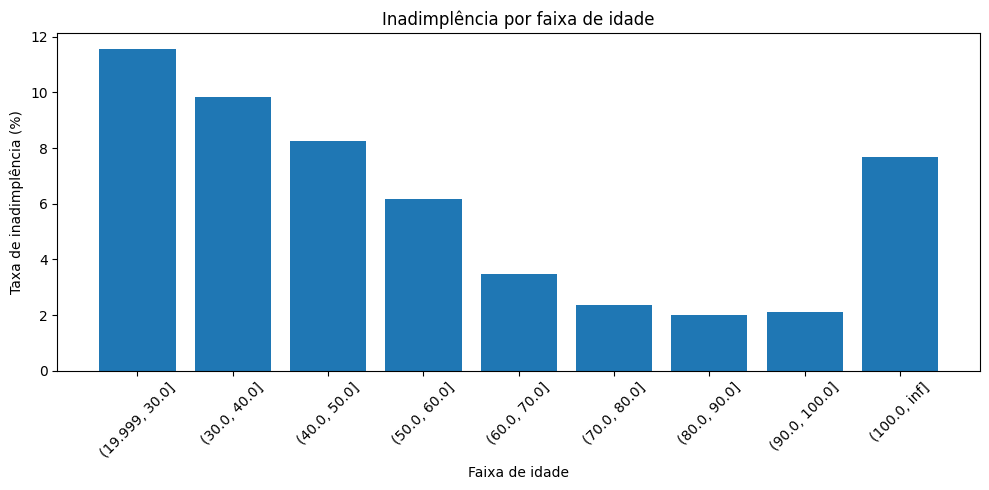

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela["Faixa"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Faixa de idade")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Inadimplência por faixa de idade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observa-se uma maior maior taxa de inadimplência na população entre 20 e 30 anos e um decréscimo na porcentagem das faixas etárias seguintes. Apesar de a faixa etária entre 100 e inf apresentar inadimplência de 7,69%, há uma população muito pequena nesse espectro para afirmar uma relação direta com o default. 

####  NumberOfTime30-59DaysPastDueNotWorse

In [ ]:
df_30_60 = df_training[
    ["NumberOfTime30-59DaysPastDueNotWorse", "SeriousDlqin2yrs"]
].copy()

resultado = df_30_60.groupby(
    "NumberOfTime30-59DaysPastDueNotWorse"
).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

resultado["Taxa_Inadimplencia"] *= 100

display(resultado)

,NumberOfTime30-59DaysPastDueNotWorse,Total,Inadimplentes,Taxa_Inadimplencia
0,0,126018,5041,4.00
1,1,16033,2409,15.03
2,2,4598,1219,26.51
3,3,1754,618,35.23
4,4,747,318,42.57
5,5,342,154,45.03
6,6,140,74,52.86
7,7,54,28,51.85
8,8,25,8,32.00
9,9,12,4,33.33


Taxa de inadimplência associada aos valores 4, 5, 6, 7 e 98 alta, com resultados em torno de 50%.
Importante perceber o comportamento dos valores 96 e 98, pois são distantes dos outros valores e possuem alta taxa de inadimplência.

#### DebtRatio

In [ ]:
bins = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40,50, 100, 200, 300, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_debt = df_training[
    ["DebtRatio", "SeriousDlqin2yrs"]
].copy()

df_debt["Faixa"] = pd.cut(
    df_debt["DebtRatio"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_debt.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(-0.001, 1.0]",114863,7735,6.73
1,"(1.0, 2.0]",4092,539,13.17
2,"(2.0, 3.0]",762,71,9.32
3,"(3.0, 4.0]",392,28,7.14
4,"(4.0, 5.0]",245,11,4.49
5,"(5.0, 6.0]",194,5,2.58
6,"(6.0, 7.0]",159,6,3.77
7,"(7.0, 8.0]",141,8,5.67
8,"(8.0, 9.0]",146,7,4.79
9,"(9.0, 10.0]",129,7,5.43


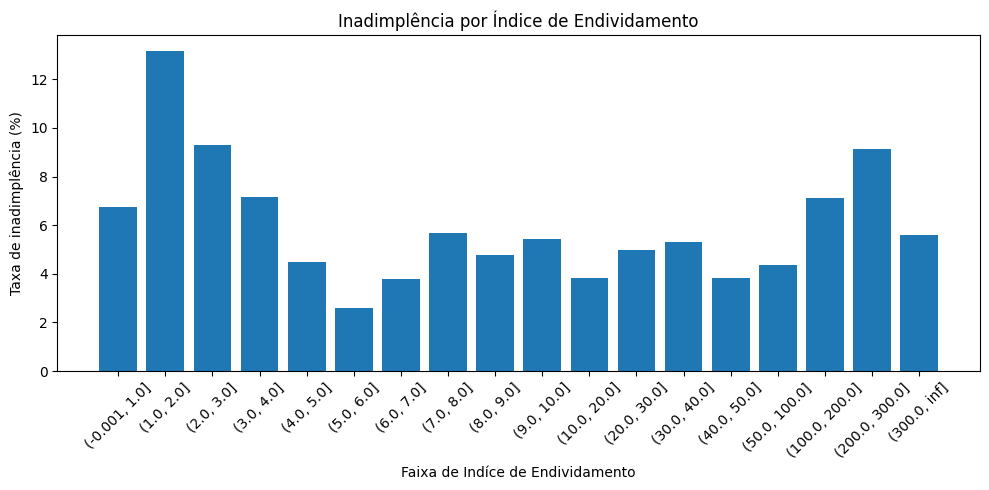

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela["Faixa"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Faixa de Indíce de Endividamento")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Inadimplência por Índice de Endividamento")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Maior taxa de inadimplência na faixa de DebtRatio entre 1 e 2 (13,17%). No entanto, nas outras faixas, a taxa de inadimplência mantém uma proximidade, sem valores expressivos.

In [ ]:
bins = [300, 500, 1000, 5000, 10000, 20000, 50000, 100000, 200000, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_debt = df_training[
    ["DebtRatio", "SeriousDlqin2yrs"]
].copy()

df_debt["Faixa"] = pd.cut(
    df_debt["DebtRatio"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_debt.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(299.999, 500.0]",1666,145,8.70
1,"(500.0, 1000.0]",3710,269,7.25
2,"(1000.0, 5000.0]",15411,717,4.65
3,"(5000.0, 10000.0]",1301,92,7.07
4,"(10000.0, 20000.0]",138,13,9.42
5,"(20000.0, 50000.0]",30,7,23.33
6,"(50000.0, 100000.0]",4,0,0.00
7,"(100000.0, 200000.0]",4,0,0.00
8,"(200000.0, inf]",4,0,0.00


Apesar do intervalo (10000.0, 20000.0] apresentar taxa de inadimplência de 23.33% não é possível concluir algo devido a baixa densidade de dados nessa faixa.

#### MonthlyIncome

In [ ]:
bins = [0, 4000, 8000, 12000, 20000, 30000, 36000, 50000, 100000, 200000, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_income = df_training[
    ["MonthlyIncome", "SeriousDlqin2yrs"]
].copy()

df_income["Faixa"] = pd.cut(
    df_income["MonthlyIncome"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_income.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(-0.001, 4000.0]",40398,3626,8.98
1,"(4000.0, 8000.0]",48420,3278,6.77
2,"(8000.0, 12000.0]",20709,964,4.65
3,"(12000.0, 20000.0]",8639,377,4.36
4,"(20000.0, 30000.0]",1311,70,5.34
5,"(30000.0, 36000.0]",233,9,3.86
6,"(36000.0, 50000.0]",258,16,6.20
7,"(50000.0, 100000.0]",231,14,6.06
8,"(100000.0, 200000.0]",41,1,2.44
9,"(200000.0, inf]",29,2,6.90


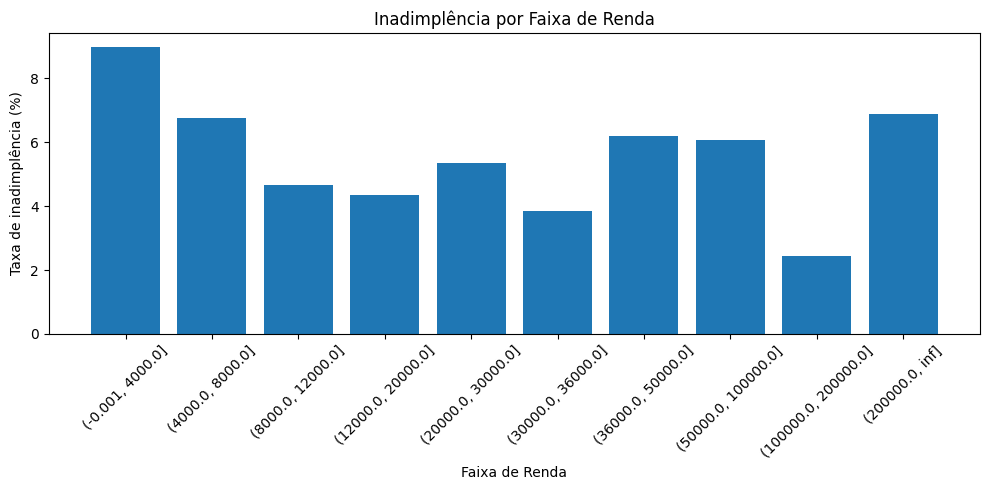

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela["Faixa"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Faixa de Renda")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Inadimplência por Faixa de Renda")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
bins = [0, 1000, 2000, 3000, 4000]

df_income["Faixa"] = pd.cut(
    df_income["MonthlyIncome"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_income.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(-0.001, 1000.0]",4795,247,5.15
1,"(1000.0, 2000.0]",7208,767,10.64
2,"(2000.0, 3000.0]",13081,1263,9.66
3,"(3000.0, 4000.0]",15314,1349,8.81


A análise de MonthlyIncome sugere uma possível relação inversa entre renda mensal e inadimplência nas faixas iniciais, nas quais a taxa de inadimplência diminui conforme a renda aumenta. Nas faixas superiores, as taxas apresentam oscilações, sem uma tendência consistente. 

MonthlyIncome entre 1000 e 2000 apresenta a maior taxa de inadimplência (10.64%).

Analisemos os valores NaN em MonthlyIncome que representam 19.82% da população.

In [ ]:
taxa = df_income.loc[
    df_income["MonthlyIncome"].isna(),
    "SeriousDlqin2yrs"
].mean() * 100

print(f"Taxa de inadimplencia associada a NaN: {taxa:.4f}%")

Taxa de inadimplencia associada a NaN: 5.6137%


In [ ]:
# Filtra o banco para pegar apenas o grupo com MonthlyIncome NÃO nulo
df_com_renda = df_training[df_training["MonthlyIncome"].notna()]

# Calcula a taxa de inadimplência desse grupo
taxa_inadimplencia_grupo = df_com_renda["SeriousDlqin2yrs"].mean()

print(f"Taxa de inadimplência de quem tem renda preenchida é: {taxa_inadimplencia_grupo:.2%}")

Taxa de inadimplência de quem tem renda preenchida é: 6.95%


Os registros com valores ausentes em MonthlyIncome apresentam uma taxa de inadimplência (5.61%) levemente inferior à taxa média de quem tem renda preenchida (6.95%).

#### NumberOfOpenCreditLinesAndLoans

In [ ]:
bins = [0, 2, 4, 6, 8, 10, 20, 30, 40, 50, np.inf]

# Selecionar a utilização de crédito e a variável-alvo da base original
df_credit = df_training[
    ["NumberOfOpenCreditLinesAndLoans", "SeriousDlqin2yrs"]
].copy()

df_credit["Faixa"] = pd.cut(
    df_credit["NumberOfOpenCreditLinesAndLoans"],
    bins=bins,
    include_lowest=True
)

# Relacionar as faixas com a variável-alvo
tabela = df_credit.groupby("Faixa", observed=False).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

display(tabela.round(2))

,Faixa,Total,Inadimplentes,Taxa_Inadimplencia
0,"(-0.001, 2.0]",12992,1678,12.92
1,"(2.0, 4.0]",20667,1425,6.90
2,"(4.0, 6.0]",26545,1573,5.93
3,"(6.0, 8.0]",25807,1353,5.24
4,"(8.0, 10.0]",20979,1238,5.90
5,"(10.0, 20.0]",39030,2480,6.35
6,"(20.0, 30.0]",3626,253,6.98
7,"(30.0, 40.0]",292,18,6.16
8,"(40.0, 50.0]",47,6,12.77
9,"(50.0, inf]",15,2,13.33


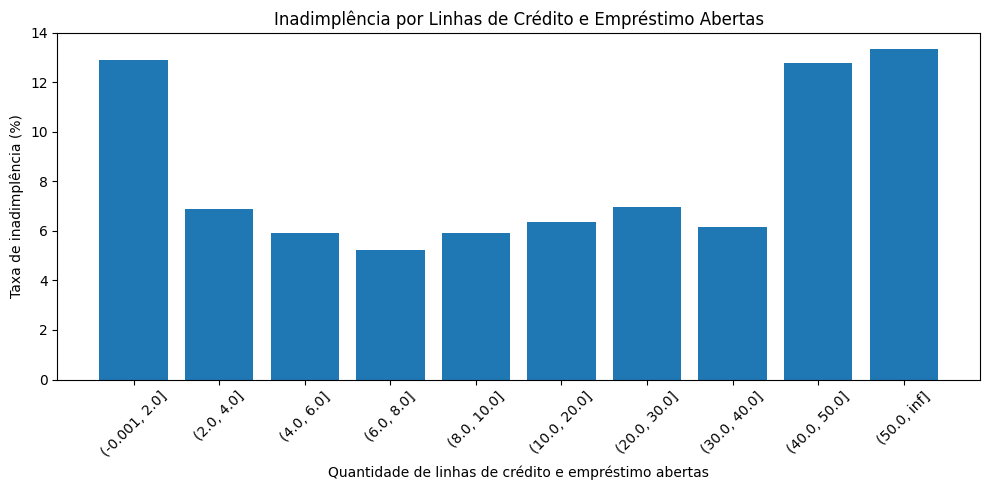

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    tabela["Faixa"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Quantidade de linhas de crédito e empréstimo abertas")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Inadimplência por Linhas de Crédito e Empréstimo Abertas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Maior taxa de inadimplência nas quantidades entre 0 e 2 de linhas de crédito e empréstimo abertas (12.92%). Entre 40 e 58 a porcentagem é parecida, no entanto a quantidade de clientes nessa faixa é pequena para concluir algo. As outras faixas mantêm uma taxa em torno de 6%. 

#### NumberOfTimes90DaysLate

In [ ]:
df_90 = df_training[
    ["NumberOfTimes90DaysLate", "SeriousDlqin2yrs"]
].copy()

resultado = df_90.groupby(
    "NumberOfTimes90DaysLate"
).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

resultado["Taxa_Inadimplencia"] *= 100

display(resultado)

,NumberOfTimes90DaysLate,Total,Inadimplentes,Taxa_Inadimplencia
0,0,141662,6554,4.63
1,1,5243,1765,33.66
2,2,1555,776,49.90
3,3,667,385,57.72
4,4,291,195,67.01
5,5,131,83,63.36
6,6,80,48,60.00
7,7,38,31,81.58
8,8,21,15,71.43
9,9,19,14,73.68


Os valores 98 e 96 com o mesmo comportamento analisado em NumberOfTimes30-60DaysLate, mesma quantidade e mesma taxa de inadimplência. Seriam as mesmas pessoas? 

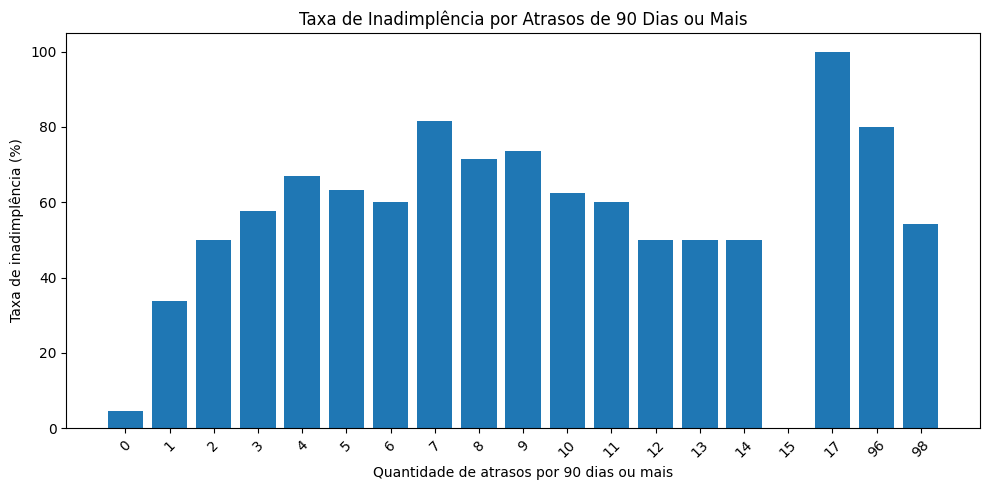

In [ ]:
# Relacionar as faixas com a variável-alvo
tabela = df_90.groupby("NumberOfTimes90DaysLate").agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

plt.figure(figsize=(10, 5))

plt.bar(
    tabela["NumberOfTimes90DaysLate"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Quantidade de atrasos por 90 dias ou mais")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Taxa de Inadimplência por Atrasos de 90 Dias ou Mais")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ademais, até o valor 5 a taxa de inadimplência cresce. A partir de 7 atrasos a densidade dos dados diminuem e não é possível concluir algo.

#### NumberRealEstateLoansOrLines

In [ ]:
df_real = df_training[
    ["NumberRealEstateLoansOrLines", "SeriousDlqin2yrs"]
].copy()

resultado = df_real.groupby(
    "NumberRealEstateLoansOrLines"
).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

resultado["Taxa_Inadimplencia"] *= 100

display(resultado)

,NumberRealEstateLoansOrLines,Total,Inadimplentes,Taxa_Inadimplencia
0,0,56188,4672,8.31
1,1,52338,2748,5.25
2,2,31522,1765,5.60
3,3,6300,422,6.70
4,4,2170,194,8.94
5,5,689,83,12.05
6,6,320,48,15.00
7,7,171,31,18.13
8,8,93,23,24.73
9,9,78,14,17.95


Valores acima de 10 com baixa densidade para concluir algo. No entanto, nota-se que inicialmente a taxa de inadimplência decresce (de 0 a 3) e depois cresce (de 4 a 8).

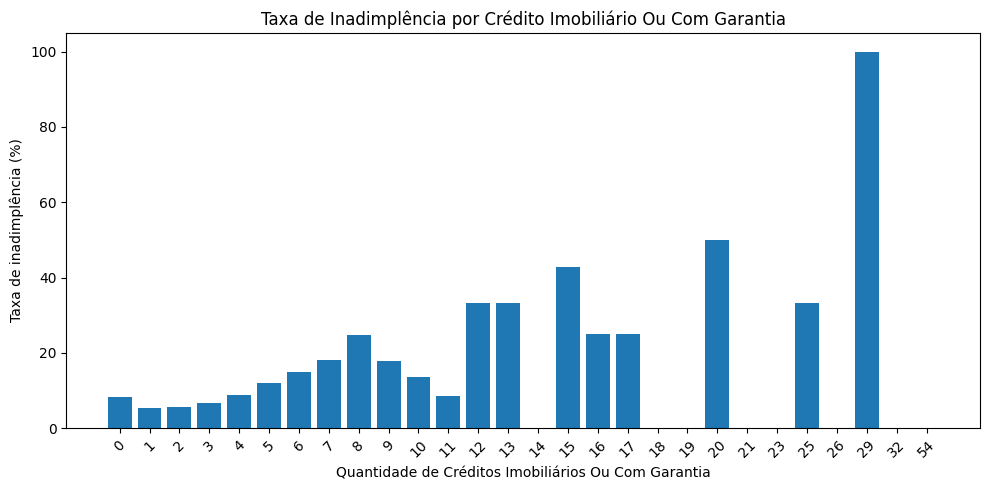

In [ ]:
# Relacionar as faixas com a variável-alvo
tabela = df_real.groupby("NumberRealEstateLoansOrLines").agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

plt.figure(figsize=(10, 5))

plt.bar(
    tabela["NumberRealEstateLoansOrLines"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Quantidade de Créditos Imobiliários Ou Com Garantia")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Taxa de Inadimplência por Crédito Imobiliário Ou Com Garantia")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### NumberOfTimes60-89DaysPastDueNotWorse

In [ ]:
df_60_89 = df_training[
    ["NumberOfTime60-89DaysPastDueNotWorse", "SeriousDlqin2yrs"]
].copy()

resultado = df_60_89.groupby(
    "NumberOfTime60-89DaysPastDueNotWorse"
).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

resultado["Taxa_Inadimplencia"] *= 100

display(resultado)

,NumberOfTime60-89DaysPastDueNotWorse,Total,Inadimplentes,Taxa_Inadimplencia
0,0,142396,7256,5.10
1,1,5731,1777,31.01
2,2,1118,561,50.18
3,3,318,180,56.60
4,4,105,65,61.90
5,5,34,21,61.76
6,6,16,12,75.00
7,7,9,5,55.56
8,8,2,1,50.00
9,9,1,0,0.00


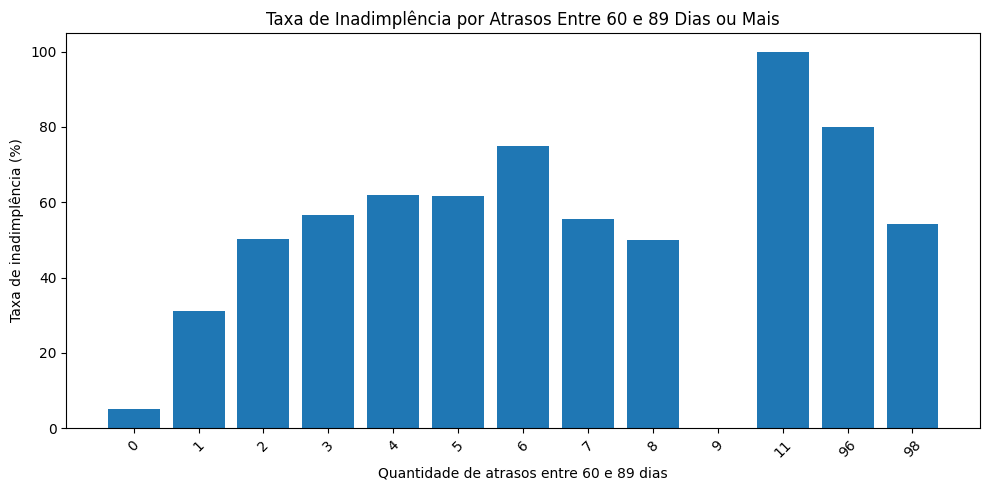

In [ ]:
# Relacionar as faixas com a variável-alvo
tabela = df_60_89.groupby("NumberOfTime60-89DaysPastDueNotWorse").agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

tabela["Taxa_Inadimplencia"] *= 100

plt.figure(figsize=(10, 5))

plt.bar(
    tabela["NumberOfTime60-89DaysPastDueNotWorse"].astype(str),
    tabela["Taxa_Inadimplencia"]
)

plt.xlabel("Quantidade de atrasos entre 60 e 89 dias")
plt.ylabel("Taxa de inadimplência (%)")
plt.title("Taxa de Inadimplência por Atrasos Entre 60 e 89 Dias ou Mais")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Note que a taxa de inadimplência cresce a medida que os atrasos aumentam até chegarmos em 6 atrasos. No entanto, os valores 6, 7, 8 e 11 apresentam uma densidade muito baixa de clientes para concluir algo. 

Mais uma vez os valores 96 e 98 com o mesmo comportamento que apresentam nas outras variáveis que analisam atrasos de pagamento. (30-60DaysLate e 90DaysLate). Seriam as mesmas pessoas?

In [ ]:
colunas = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

display(df_training[colunas].loc[
    df_training[colunas].isin([96, 98]).any(axis=1)
])

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
1733,98,98,98
2286,98,98,98
3884,98,98,98
4417,98,98,98
4705,98,98,98
...,...,...,...
147774,98,98,98
149153,98,98,98
149239,98,98,98
149439,98,98,98


Suspeito!

In [ ]:
colunas = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Clientes que possuem 98 em pelo menos uma variável
tem_98 = df_training[colunas].eq(98).any(axis=1)

# Entre eles, verificar se todas as três variáveis são iguais a 98
todas_98 = df_training[colunas].eq(98).all(axis=1)

# Registros que têm 98 em algumas, mas não em todas
inconsistentes = df_training.loc[tem_98 & ~todas_98, colunas]

print("Clientes com 98 em pelo menos uma variável:", tem_98.sum())
print("Clientes com 98 nas três variáveis:", todas_98.sum())
print("Clientes que não têm 98 nas três:", len(inconsistentes))

#display(inconsistentes)

Clientes com 98 em pelo menos uma variável: 264
Clientes com 98 nas três variáveis: 264
Clientes que não têm 98 nas três: 0


In [ ]:
filtro_96 = (df_training[colunas] == 96).all(axis=1)

display(df_training.loc[filtro_96, colunas])

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
41944,96,96,96
69478,96,96,96
84167,96,96,96
94106,96,96,96
120049,96,96,96


Ou seja, quem tem 96 ou 98 em uma das variáveis de atraso possui em todas as outras!

In [ ]:
colunas_atraso = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for coluna in colunas_atraso:
    print(f"\nVariável: {coluna}")

    analise = (
        df_training.loc[df_training[coluna].isin([96, 98])]
        .groupby(coluna)["SeriousDlqin2yrs"].agg( quantidade="count", inadimplentes="sum",taxa_inadimplencia="mean"))
        
analise["taxa_inadimplencia"] *= 100
print(analise.round(2))



Variável: NumberOfTime30-59DaysPastDueNotWorse

Variável: NumberOfTime60-89DaysPastDueNotWorse

Variável: NumberOfTimes90DaysLate
                         quantidade  inadimplentes  taxa_inadimplencia
NumberOfTimes90DaysLate                                               
96                                5              4               80.00
98                              264            143               54.17


#### NumberOfDependents

In [ ]:
df_dependents = df_training[
    ["NumberOfDependents", "SeriousDlqin2yrs"]
].copy()

resultado = df_dependents.groupby(
    "NumberOfDependents"
).agg(
    Total=("SeriousDlqin2yrs", "count"),
    Inadimplentes=("SeriousDlqin2yrs", "sum"),
    Taxa_Inadimplencia=("SeriousDlqin2yrs", "mean")
).reset_index()

resultado["Taxa_Inadimplencia"] *= 100

display(resultado)

,NumberOfDependents,Total,Inadimplentes,Taxa_Inadimplencia
0,0.00,86902,5095,5.86
1,1.00,26316,1935,7.35
2,2.00,19522,1584,8.11
3,3.00,9483,837,8.83
4,4.00,2862,297,10.38
5,5.00,746,68,9.12
6,6.00,158,24,15.19
7,7.00,51,5,9.80
8,8.00,24,2,8.33
9,9.00,5,0,0.00


A maior de taxa de inadimplência aparece na população com número de dependentes igual a 6 (15.19%). No entanto, a taxa tem um comportamento crescente a medida que a quantidade de dependentes aumenta de 0 para 4.

Analisemos a população com informação NaN nesse campo.

In [ ]:
taxa = df_dependents.loc[
    df_dependents["NumberOfDependents"].isna(),
    "SeriousDlqin2yrs"
].mean() * 100

print(f"Taxa de inadimplencia associada a NaN: {taxa:.4f}%")

Taxa de inadimplencia associada a NaN: 4.5617%


In [ ]:
# Filtra o banco para pegar apenas o grupo com NumberOfDepedents NÃO nulo
df_com_valor = df_training[df_training["NumberOfDependents"].notna()]

# Calcula a taxa de inadimplência desse grupo
taxa_inadimplencia_grupo = df_com_valor["SeriousDlqin2yrs"].mean()

print(f"Taxa de inadimplência de quem tem dependentes declarados é: {taxa_inadimplencia_grupo:.2%}")

Taxa de inadimplência de quem tem dependentes declarados é: 6.74%


Taxa relativamente abaixo do dataset.

## Síntese dos Resultados Obtidos

### Resultados Gerais

`SeriousDlqin2yrs`: Desbalanceamento da variável alvo! Apenas 6.68% inadimplente.

`Unnamed:` Variável que aparentemente associa um ID a um cliente. Não possui relevância no aumento ou redução da taxa de inadimplência, uma vez que se trata de um ID único e, portanto, não foi analisado.

`RevolvingUtilizationOfUnsecuredLines`: 75% da população, ou pelo menos 112.500 pessoas, possui Revolving até 0.56. Por outro lado, há 172 clientes com Revolving maior que 1000. Assim, conseguimos ver a amplitude dos dados nessa variável e a concentração da taxa em valores menores a 1%. Ademais, pessoas com Revolving entre 1 e 2 apresentam maior taxa de inadimplência quando comparada com outras faixas. Os valores extremos da variável foram analisados e não indicaram uma relação direta com o aumento ou a redução da taxa de inadimplência, assim, em primeiro momento, os valores acima de 2 serão limitados (clip) no tratamento de dados e uma flag indicará utilização acima do limite (ver seção de tratamento). 

`Age`: 50% da população tem até 52 anos, enquanto 75% tem até 62 anos. Ademais, a idade mínima aceitável é de 21 anos. Há um cliente com idade registrada como 0, mas aparenta ser erro na qualidade dos dados. Dessa forma, faremos um tratamento semelhate ao realizado com os valores extremos em RevolvingUtilizationOfUnsecuredLines. Por outro lado, a maior taxa de inadimplência encontra-se na população entre 20 e 30 anos, apesar de a maior parte da população se encontrar na faixa dos 40 a 50 anos. 

`NumberOfTime30-59DaysPastDueNotWorse`: 75% da população possui 0 atrasos. Há de 0 a 13 atrasos registrados. Além disso, há dois valores interessantes,o 96 e o 98, que obtiveram um comportamento idêntico nas outras variáveis de atraso. A análise de como tratar tais valores é feita mais adiante.Ademais, pessoas com 0 atrasos apresentaram uma taxa de inadimplência consideravelmente menor (4%) se comparada com os outros grupos (15% para cima). No entanto, notou-se uma crescente na taxa de inadimplência a medida em que a quantidade de atrasos aumentava. Faixas de valores com baixa densidade de dados não auxiliam na conclusão com maior assertividade, o que ocorreu em valores mais altos. 

`DebtRatio`: 75% da população possui um indíce de endividamento de até 0.87. Foi observado que valores muito altos de DebtRatio estão associadas a valores ausentes na variável MonthlyIncome, com uma taxa de 94.3% de ocorrência. Assim, no tratamento de dados, o DebtRatio só será usado como razão quando houver renda; sem renda, o valor é tratado como dívida absoluta e a dívida mensal é reconstruída para todos os clientes.

`MonthlyIncome`: 50% da população ganha até 5400 por mês, enquanto 75% ganha até 8249. No entanto, o valor máximo se encontra em 3008750. Ademais, notou-se uma queda na taxa de inadimplência a medida em que a renda mensal aumentava. A taxa de inadimplência mostrou-se maior principalmente na faixa entre 1000 e 2000. Além disso, a variável apresenta valores NaN que terão a síntese de sua análise de forma separada mais adiante.

`NumberOfOpenCreditLinesAndLoans`: 25% da população possui até 5 linhas de crédito e de empréstimos abertas, enquanto 50% apresentam até 8 e 75%, até 11. No entanto, a maior taxa de inadimplência observada se encontrou na faixa entre 0 e 2. Ademais, nos outros intervalos a taxa de inadimplência se apresentou similar, girando em torno de 6%.

`NumberOfTimes90DaysLate`: 75% da população possui 0 atrasos. Há de 0 a 17 atrasos registrados. Além disso, há dois valores interessantes,o 96 e o 98, que obtiveram um comportamento idêntico nas outras variáveis de atraso. A análise de como tratar tais valores é feita mais adiante. Ademais, pessoas com 0 atrasos apresentaram uma taxa de inadimplência consideravelmente menor (4.63%) se comparada com os outros grupos (30% para cima). No entanto, notou-se uma crescente na taxa de inadimplência a medida em que a quantidade de atrasos aumentava. Faixas de valores com baixa densidade de dados não auxiliam na conclusão com maior assertividade, o que acontece com valores mais altos. 

`NumberRealEstateLoansOrLines`: 25% da população possui até 0 empréstimos imobiliários ou crédito com garantia de imóvel, enquanto 50% apresentam até 1 e 75% até 2. Nota-se uma tendência ao crescimento do aumento da taxa de inadimplência a medida que o valor de NumberRealEstateLoansOrLines aumenta. 

`NumberOfTime60-89DaysPastDueNotWorse`: 75% da população possui 0 atrasos. Há de 0 a 11 atrasos registrados. Além disso, há dois valores interessantes,o 96 e o 98, que obtiveram um comportamento idêntico nas outras variáveis de atraso. A análise de como tratar tais valores é feita mais adiante. Ademais, pessoas com 0 atrasos apresentaram uma taxa de inadimplência consideravelmente menor (5%) se comparada com os outros grupos (30% para cima). No entanto, notou-se uma crescente na taxa de inadimplência a medida em que a quantidade de atrasos aumentava. Faixas de valores com baixa densidade de dados não auxiliam na conclusão com maior assertividade, o que acontece com valores mais altos. 

`NumberOfDependents`: 50% da população possui até 0 dependentes e 75% possui até 1 dependente. Ademais, notou-se uma tendência no aumento da taxa de inadimplência a media em que a quantidade de dependentes amentava. Além disso, a variável apresenta valores NaN que terão a síntese de sua análise de forma separada mais adiante.

### `Age` = 0?

Há apenas um registro em `age` com valor igual a zero, o que é inconsistente com o negócio, já que não faz sentido um cliente de crédito com 0 anos. Trata-se de um problema de qualidade dos dados, e não há informação suficiente para determinar a faixa etária real desse cliente.
Por ser um caso isolado (1 em ~150 mil registros), qualquer comparação de desempenho entre manter o valor ou substituí-lo seria dominada por ruído. A decisão foi tratar o zero como valor ausente e substituí-lo pela mediana das idades calculada apenas no conjunto de treino. Não foi criada coluna indicadora, pois um único caso não oferece sinal estatístico para o modelo.

### Valores extremos de `RevolvingUtilizationOfUnsecuredLines`

Foram identificados 172 registros com valores de `RevolvingUtilizationOfUnsecuredLines` superiores a 1.000. Apesar de serem valores extremos em relação à distribuição geral da variável, a análise das 50 maiores observações revelou apenas dois casos de inadimplência.

Para compreender melhor o perfil desses clientes, foram analisadas as medianas de outras variáveis. O grupo apresentou renda mensal mediana de 7.041,50, superior à mediana geral de 5.400,00. Além disso, a mediana de `DebtRatio` foi de 0,38, enquanto as medianas das variáveis relacionadas a atrasos foram iguais a zero.

Esses resultados sugerem que os clientes com valores extremos de revolving não apresentam, necessariamente, as características geralmente associadas às maiores taxas de inadimplência identificadas nas análises anteriores. Entretanto, as medianas representam o comportamento central de cada variável e não permitem afirmar que todos os clientes desse grupo possuem essas características.

No entanto, notou-se que 99% possui um Revolving de até 1.09, enquanto, 99.9% possui até 1571 (salto considerável). Assim, tais valores podem ser considerados outliers e serão limitados (clip) em 2 no tratamento de dados, com uma flag indicando utilização acima do limite. Substituir pela mediana faria clientes com utilização absurda parecerem de baixo risco. 

### Valores NaN em `MonthlyIncome` e em `NumberOfDepedents`

Os clientes com NaN em `NumberOfDepedents` apresentaram uma taxa de inadimplência menor (4.56%) se comparada com os valores preenchidos, em que a taxa média é 6.74%. 

Ademais, em `MonthlyIncome` a taxa de inadimplência do grupo com NaN também se apresentou menor do que a taxa média do grupo com valor numérico. Os valores NaN apresentaram taxa em torno de 5.6%, enquanto os valores preenchidos apresentaram 6.9%, aproximadamente. 

Assim, na etapa de tratamento de dados, os valores NaN serão tratados dentro do pipeline de modelagem (mediana aprendida só no treino na regressão logística; tratamento nativo no gradient boosting) e uma nova variável surgirá para indicar se aquele valor havia sido preenchido com NaN ou não anteriormente, visto que as porcentagens apresentam uma certa discrepância.

### Valores **96** e **98** nas variáveis de atraso (`NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse`, `NumberOfTimes90DaysLate`)

Foi observado que os valores 96 e 98 aparecem simultaneamente nas três variáveis relacionadas a atrasos. Esse padrão sugere que podem representar códigos especiais, e não contagens reais de atrasos. Dessa forma, tais valores serão convertidos em NaN (imputados pela mediana do treino na regressão logística) e haverá a criação de uma nova coluna indicando que ali existiam os valores 96 ou 98. Vale ressaltar que 96 e 98 serão tratados juntos devido a semelhança de comportamento e a baixa densidade de valores 96 (apenas 4).

## Tratamento de dados e engenharia de atributos

Todas as decisões do EDA foram reunidas no módulo `risklab_features.py` (função `prepara_features`), que **não aprende nada dos dados** (sem medianas nem percentis calculados na base). Por isso ela pode ser aplicada antes do split sem vazamento, e a mesma função será reutilizada pela interface que consulta clientes novos.

| Problema encontrado no EDA | Tratamento |
|---|---|
| Códigos 96/98 nas 3 colunas de atraso (não são contagens) | viram `NaN` + flag `atraso_codigo_especial` |
| `age = 0` | vira `NaN` |
| Revolving com valores absurdos (até 50.708; p99 = 1,09) | limitado (`clip`) em 2 + flag `revolving_acima_1` (utilização acima do limite) |
| `DebtRatio` é dívida **absoluta** quando falta renda | `debtratio` só é razão quando há renda; a dívida mensal é reconstruída para todos (`log_divida_mensal`) |
| `MonthlyIncome` e `NumberOfDependents` ausentes | `NaN` + flags `renda_ausente` e `dependentes_ausentes` |
| Rendas muito assimétricas | `log1p` |

Também foram criados atributos novos: `total_atrasos`, `atraso_ponderado` (atrasos mais longos pesam mais) e `log_renda_por_dependente`.

**Imputação e padronização** (que *aprendem* com os dados) ficam dentro do `Pipeline` e são ajustadas apenas no treino de cada fold da validação cruzada. O gradient boosting trata `NaN` nativamente e dispensa ambas.

**Sem SMOTE.** O SMOTE distorce as probabilidades (o Brier Score da versão anterior era pior que prever sempre a taxa média). Como o RiskLab entrega uma *probabilidade de inadimplência* ao analista, mantemos a distribuição real das classes e tratamos a decisão no **limiar**, escolhido por custo de negócio.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
    confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from risklab_features import FEATURES, prepara_features

#### Separar alvo e atributos, e dividir treino/teste

O conjunto de **teste (25%)** só é usado no final, para a avaliação. Escolha de hiperparâmetros, calibração e limiar usam apenas o treino (com validação cruzada).

In [ ]:
ALVO = "SeriousDlqin2yrs"

df_raw = df_training.drop(columns=["Unnamed: 0"])
X_all = prepara_features(df_raw.drop(columns=[ALVO]))
y_all = df_raw[ALVO]

x_train, x_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=42, stratify=y_all
)

print(f"Treino: {x_train.shape} | Teste: {x_test.shape}")
print(f"Inadimplência treino: {y_train.mean():.2%} | teste: {y_test.mean():.2%}")

# Percentual de ausentes por atributo (tratados dentro do pipeline)
ausentes = (x_train.isna().mean() * 100).round(2)
display(ausentes[ausentes > 0].rename("% ausente").to_frame())

## Modelagem

Dois modelos são comparados com **validação cruzada estratificada (5 folds)** no treino:

1. **Regressão Logística** (baseline interpretável): imputação pela mediana + padronização + ajuste do parâmetro de regularização `C`.
2. **Gradient Boosting** (`HistGradientBoostingClassifier`): captura as relações não lineares e em "U" vistas no EDA (imóveis, linhas abertas, revolving), com busca aleatória de hiperparâmetros e *early stopping*.

A métrica de seleção é a **ROC-AUC média na validação cruzada**, nunca o teste.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1) Regressão Logística
pipe_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=2000)),
])

busca_lr = GridSearchCV(
    pipe_lr,
    param_grid={"modelo__C": [0.01, 0.1, 1, 10]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
busca_lr.fit(x_train, y_train)
print("Melhor C:", busca_lr.best_params_)

In [ ]:
# 2) Gradient Boosting
hgb = HistGradientBoostingClassifier(
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
    max_iter=500, random_state=0,
)

espaco = {
    "learning_rate": [0.03, 0.05, 0.08],
    "max_leaf_nodes": [15, 31],
    "max_depth": [3, 4, 6, None],
    "min_samples_leaf": [50, 100, 200],
    "l2_regularization": [0.0, 1.0, 10.0],
}

busca_gb = RandomizedSearchCV(
    hgb, espaco, n_iter=10, scoring="roc_auc", cv=3,
    random_state=42, n_jobs=-1,
)
busca_gb.fit(x_train, y_train)
print("Melhores hiperparâmetros:", busca_gb.best_params_)

In [ ]:
def resumo_cv(busca, nome):
    i = busca.best_index_
    return {
        "Modelo": nome,
        "ROC-AUC (CV, média)": busca.cv_results_["mean_test_score"][i],
        "Desvio entre folds": busca.cv_results_["std_test_score"][i],
    }

tabela_cv = pd.DataFrame([
    resumo_cv(busca_lr, "Regressão Logística"),
    resumo_cv(busca_gb, "Gradient Boosting"),
]).set_index("Modelo")
display(tabela_cv.round(4))

nome_final = tabela_cv["ROC-AUC (CV, média)"].idxmax()
print(f"\nModelo selecionado pela validação cruzada: {nome_final}")

#### Calibração das probabilidades

Um score só serve como "probabilidade de inadimplência" se uma previsão de 20% corresponder a ~20% de inadimplentes na prática. Aplicamos calibração **isotônica** (com validação cruzada interna) sobre cada modelo e comparamos o Brier Score antes e depois.

In [ ]:
bases = {
    "Regressão Logística": busca_lr.best_estimator_,
    "Gradient Boosting": busca_gb.best_estimator_,
}

modelos_cal = {
    nome: CalibratedClassifierCV(clone(base), method="isotonic", cv=5).fit(x_train, y_train)
    for nome, base in bases.items()
}
modelo_final = modelos_cal[nome_final]
print("Modelos calibrados.")

## Avaliação no conjunto de teste

Além de ROC-AUC, PR-AUC e Brier, usamos as métricas padrão em risco de crédito:

- **Gini** = 2·AUC − 1
- **KS**: separação máxima entre as distribuições de bons e maus pagadores
- **Brier de referência**: erro de prever sempre a taxa média de inadimplência (qualquer modelo útil deve ficar abaixo dele)

In [ ]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def avalia(y, p):
    auc = roc_auc_score(y, p)
    return {
        "ROC-AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_stat(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
    }

def ic_auc(y, p, n=300, seed=0):
    # Intervalo de confiança (95%) da ROC-AUC por bootstrap
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    aucs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            aucs.append(roc_auc_score(y[i], p[i]))
    return np.percentile(aucs, [2.5, 97.5])

linhas = {}
for nome in bases:
    linhas[f"{nome} (bruta)"] = avalia(y_test, bases[nome].predict_proba(x_test)[:, 1])
    linhas[f"{nome} (calibrada)"] = avalia(y_test, modelos_cal[nome].predict_proba(x_test)[:, 1])

resultados = pd.DataFrame(linhas).T
display(resultados.round(4))

brier_ref = y_test.mean() * (1 - y_test.mean())
print(f"Brier de referência (prever sempre a taxa média): {brier_ref:.4f}")

p_test = modelo_final.predict_proba(x_test)[:, 1]
lo, hi = ic_auc(y_test, p_test)
print(f"\n{nome_final} (calibrada) - ROC-AUC no teste: {roc_auc_score(y_test, p_test):.4f}  (IC 95%: {lo:.4f} a {hi:.4f})")

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

# Curva ROC
for nome, m in modelos_cal.items():
    p = m.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    eixos[0].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_test, p):.3f})")
eixos[0].plot([0, 1], [0, 1], "--", color="gray")
eixos[0].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos", title="Curva ROC (teste)")
eixos[0].legend(); eixos[0].grid(alpha=.3)

# Curva de calibração (faixas com o mesmo número de clientes)
for nome, m in modelos_cal.items():
    p = m.predict_proba(x_test)[:, 1]
    real, previsto = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    eixos[1].plot(previsto, real, marker="o", label=nome)
eixos[1].plot([0, 1], [0, 1], "--", color="gray", label="Calibração perfeita")
eixos[1].set(xlabel="Probabilidade média prevista", ylabel="Frequência real de inadimplência", title="Calibração (teste)")
eixos[1].legend(); eixos[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

#### Interpretação do baseline: Regressão Logística

Como os atributos são padronizados, cada coeficiente mostra o efeito de **+1 desvio padrão** do atributo sobre o *log-odds* de inadimplência. A coluna `Razão de chances` é `exp(coeficiente)`: valores acima de 1 aumentam o risco.

In [ ]:
coefs = busca_lr.best_estimator_.named_steps["modelo"].coef_[0]

tabela_coef = pd.DataFrame({
    "Coeficiente": coefs,
    "Razão de chances (+1 DP)": np.exp(coefs),
}, index=FEATURES).sort_values("Coeficiente", key=np.abs, ascending=False)

display(tabela_coef.round(3))

## Decisão de negócio: escolha do limiar por custo

O limiar padrão de 0,5 é arbitrário e, com apenas ~7% de inadimplentes, quase nunca recusa ninguém. Em crédito, os dois erros não custam o mesmo:

- **Aprovar um inadimplente** → perda do valor emprestado (custo alto);
- **Recusar um bom pagador** → perda da margem do negócio (custo menor).

Os custos abaixo são **relativos e ilustrativos**: a empresa deve substituí-los pelos valores reais (perda esperada por operação e margem por cliente). Para probabilidades calibradas, o limiar ótimo teórico é `custo_bom / (custo_bom + custo_inad)`, o que serve de verificação.

O limiar é escolhido com previsões *out-of-fold* do **treino**, sem tocar no teste.

In [ ]:
CUSTO_INADIMPLENTE = 10.0   # custo relativo de aprovar quem não paga
CUSTO_BOM_RECUSADO = 1.0    # custo relativo de recusar quem pagaria

def custo_total(y, p, limiar, c_inad, c_bom):
    y = np.asarray(y)
    recusa = np.asarray(p) >= limiar
    inad_aprovado = ((~recusa) & (y == 1)).sum()
    bom_recusado = (recusa & (y == 0)).sum()
    return c_inad * inad_aprovado + c_bom * bom_recusado

# Previsões fora da amostra no treino (cada cliente é previsto por um modelo que não o viu)
p_oof = cross_val_predict(clone(modelo_final), x_train, y_train, cv=cv, method="predict_proba")[:, 1]

limiares = np.arange(0.01, 0.61, 0.005)
custos = np.array([custo_total(y_train, p_oof, t, CUSTO_INADIMPLENTE, CUSTO_BOM_RECUSADO) for t in limiares])
t_star = round(float(limiares[np.argmin(custos)]), 3)

print(f"Limiar ótimo (custo {CUSTO_INADIMPLENTE:.0f}:{CUSTO_BOM_RECUSADO:.0f}): {t_star:.3f}")
print(f"Limiar teórico para probabilidades calibradas: {CUSTO_BOM_RECUSADO / (CUSTO_BOM_RECUSADO + CUSTO_INADIMPLENTE):.3f}")

plt.figure(figsize=(8, 4.5))
plt.plot(limiares, custos / len(y_train))
plt.axvline(t_star, color="red", linestyle="--", label=f"Limiar ótimo = {t_star:.3f}")
plt.xlabel("Limiar de recusa (probabilidade)")
plt.ylabel("Custo médio por cliente")
plt.title("Custo de negócio por limiar (treino, out-of-fold)")
plt.legend(); plt.grid(alpha=.3)
plt.show()

In [ ]:
# Sensibilidade: o que muda se a razão entre os custos for outra?
sens = []
y_tr = np.asarray(y_train)
for razao in [3, 5, 10, 20]:
    cs = [custo_total(y_tr, p_oof, t, razao, 1.0) for t in limiares]
    t = limiares[int(np.argmin(cs))]
    recusa = p_oof >= t
    sens.append({
        "Custo inadimplente / custo bom recusado": razao,
        "Limiar ótimo": round(float(t), 3),
        "% de clientes recusados": round(recusa.mean() * 100, 1),
        "% dos inadimplentes barrados": round((recusa & (y_tr == 1)).sum() / (y_tr == 1).sum() * 100, 1),
    })
display(pd.DataFrame(sens).set_index("Custo inadimplente / custo bom recusado"))

#### Desempenho da política de crédito no teste

Comparação com as duas políticas ingênuas: **aprovar todos** e **recusar todos**.

In [ ]:
y_te = np.asarray(y_test)
recusa = p_test >= t_star
y_pred = recusa.astype(int)

cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Aprovado", "Recusado"]).plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusão no teste (limiar = {t_star:.3f})")
plt.xlabel("Decisão do modelo"); plt.ylabel("Situação real (0 = pagou, 1 = inadimplente)")
plt.show()

aprovados = ~recusa
print(f"Precision (dos recusados, % realmente inadimplentes): {precision_score(y_te, y_pred):.2%}")
print(f"Recall    (dos inadimplentes, % barrados):            {recall_score(y_te, y_pred):.2%}")
print(f"% de clientes recusados:                              {recusa.mean():.2%}")
print(f"Inadimplência entre os APROVADOS: {y_te[aprovados].mean():.2%}  (base total: {y_te.mean():.2%})")

c_modelo = custo_total(y_te, p_test, t_star, CUSTO_INADIMPLENTE, CUSTO_BOM_RECUSADO)
c_aprova_todos = CUSTO_INADIMPLENTE * (y_te == 1).sum()
c_recusa_todos = CUSTO_BOM_RECUSADO * (y_te == 0).sum()
melhor_ingenua = min(c_aprova_todos, c_recusa_todos)

print(f"\nCusto (unidades relativas): modelo = {c_modelo:,.0f} | aprovar todos = {c_aprova_todos:,.0f} | recusar todos = {c_recusa_todos:,.0f}")
print(f"Redução de custo vs. melhor política ingênua: {(1 - c_modelo / melhor_ingenua):.1%}")

#### Faixas de risco e tabela de decis

O analista de crédito precisa de uma leitura simples do score. Os decis ordenam os clientes do **mais arriscado (decil 1)** ao menos arriscado (decil 10): um bom modelo concentra a inadimplência nos primeiros decis e acerta a taxa real em cada um.

In [ ]:
tab = pd.DataFrame({"y": y_te, "p": p_test})
tab["decil"] = pd.qcut(tab["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))

decis = tab.groupby("decil", observed=True).agg(
    clientes=("y", "size"),
    inadimplentes=("y", "sum"),
    prob_media_prevista=("p", "mean"),
    taxa_real=("y", "mean"),
)
decis["% inadimplentes capturados"] = decis["inadimplentes"] / decis["inadimplentes"].sum()
decis["% capturado acumulado"] = decis["% inadimplentes capturados"].cumsum()
decis["lift"] = decis["taxa_real"] / y_te.mean()

fmt = decis.copy()
for c in ["prob_media_prevista", "taxa_real", "% inadimplentes capturados", "% capturado acumulado"]:
    fmt[c] = (fmt[c] * 100).round(1).astype(str) + "%"
fmt["lift"] = fmt["lift"].round(2)
display(fmt)

x_pos = np.arange(1, 11)
plt.figure(figsize=(9, 4.5))
plt.bar(x_pos - 0.2, decis["taxa_real"] * 100, width=0.4, label="Taxa real")
plt.bar(x_pos + 0.2, decis["prob_media_prevista"] * 100, width=0.4, label="Probabilidade prevista")
plt.xticks(x_pos)
plt.xlabel("Decil de risco (1 = mais arriscado)")
plt.ylabel("Inadimplência (%)")
plt.title("Taxa real x probabilidade prevista por decil (teste)")
plt.legend(); plt.grid(alpha=.3, axis="y")
plt.show()

In [ ]:
# Faixas de risco definidas a partir das previsões out-of-fold do treino
FAIXAS = ["Baixo", "Moderado", "Alto", "Muito alto"]
cortes = np.quantile(p_oof, [0.50, 0.80, 0.95])

def faixa_risco(p):
    return np.array(FAIXAS)[np.digitize(p, cortes)]

faixas_teste = pd.DataFrame({"faixa": faixa_risco(p_test), "y": y_te})
resumo_faixas = faixas_teste.groupby("faixa").agg(
    clientes=("y", "size"), inadimplentes=("y", "sum"), taxa_real=("y", "mean")
).loc[FAIXAS]
resumo_faixas["taxa_real"] = (resumo_faixas["taxa_real"] * 100).round(2).astype(str) + "%"
display(resumo_faixas)

## Interpretabilidade com SHAP

O SHAP mostra **quanto cada atributo empurra a probabilidade de inadimplência de cada cliente para cima ou para baixo**. Aqui é aplicado diretamente sobre o modelo final calibrado (saída em probabilidade), usando o explicador de permutação, que funciona com qualquer modelo.

> Requer `pip install shap`. A explicação usa uma amostra de 300 clientes de teste para manter o tempo de execução razoável.

In [ ]:
try:
    import shap

    amostra = x_test.sample(300, random_state=0)
    fundo = x_train.sample(100, random_state=0)

    def prob_inadimplencia(dados):
        return modelo_final.predict_proba(pd.DataFrame(np.asarray(dados), columns=FEATURES))[:, 1]

    explicador = shap.Explainer(prob_inadimplencia, fundo, algorithm="permutation")
    shap_values = explicador(amostra, max_evals=2 * len(FEATURES) + 1 + 200)

    shap.plots.beeswarm(shap_values, max_display=15, show=False)
    plt.title("Impacto dos atributos na probabilidade de inadimplência")
    plt.tight_layout(); plt.show()

    shap.plots.bar(shap_values, max_display=15, show=False)
    plt.title("Importância média absoluta (SHAP)")
    plt.tight_layout(); plt.show()
except ImportError:
    print("Biblioteca shap não instalada. Execute: pip install shap")

In [ ]:
# Explicação individual: o cliente de maior risco da amostra (útil para o analista)
try:
    i_risco = int(np.argmax(prob_inadimplencia(amostra)))
    shap.plots.waterfall(shap_values[i_risco], max_display=12, show=False)
    plt.title("Por que este cliente tem risco elevado?")
    plt.tight_layout(); plt.show()
except NameError:
    print("Execute a célula anterior (SHAP) primeiro.")

## Pipeline final e exportação

Junta a engenharia de atributos e o modelo calibrado em **um único objeto** que recebe os dados *brutos* de um cliente (as 10 colunas originais) e devolve a probabilidade de inadimplência. É esse arquivo que a interface vai carregar. Uma verificação confirma que o pipeline exportado reproduz exatamente as previsões do teste.

In [ ]:
X_bruto = df_raw.drop(columns=[ALVO])

ft = FunctionTransformer(prepara_features, validate=False).fit(X_bruto)
pipeline_final = Pipeline([("features", ft), ("modelo", modelo_final)])

# Verificação: dados brutos -> pipeline == previsões já calculadas
p_check = pipeline_final.predict_proba(X_bruto.loc[x_test.index])[:, 1]
assert np.allclose(p_check, p_test), "O pipeline exportado diverge das previsões do teste!"
print("Pipeline verificado: reproduz as previsões do teste.")

# Cliente "típico" (medianas), usado pela interface para explicar quais fatores pesam no risco
referencia = {c: float(v) for c, v in X_bruto.median().items()}
referencia["DebtRatio"] = float(X_bruto.loc[X_bruto["MonthlyIncome"].notna(), "DebtRatio"].median())

artefato = {
    "pipeline": pipeline_final,
    "modelo": nome_final,
    "limiar_recusa": t_star,
    "faixas": FAIXAS,
    "cortes_faixas": cortes.tolist(),
    "custos_relativos": {"inadimplente": CUSTO_INADIMPLENTE, "bom_recusado": CUSTO_BOM_RECUSADO},
    "features": FEATURES,
    # Informações extras usadas pela interface (Streamlit)
    "metricas_teste": {k: float(v) for k, v in avalia(y_test, p_test).items()},
    "ic_auc_teste": [float(v) for v in ic_auc(y_test, p_test)],
    "n_teste": int(len(y_test)),
    "taxa_base": float(y_train.mean()),
    "taxa_real_faixa": {k: float(v) for k, v in faixas_teste.groupby("faixa")["y"].mean().items()},
    "referencia": referencia,
}
joblib.dump(artefato, "risklab_modelo.joblib")
print("Salvo em risklab_modelo.joblib (para carregar, risklab_features.py precisa estar no mesmo diretório).")

NameError: name 'df_raw' is not defined

In [ ]:
def consulta_cliente(dados: dict) -> dict:
    # Recebe os dados brutos de um cliente e devolve o risco estimado
    linha = pd.DataFrame([dados])
    p = float(artefato["pipeline"].predict_proba(linha)[:, 1][0])
    faixa = artefato["faixas"][int(np.digitize(p, artefato["cortes_faixas"]))]
    sugestao = "Recusar / encaminhar para análise" if p >= artefato["limiar_recusa"] else "Aprovar"
    return {"probabilidade_inadimplencia": round(p, 4), "faixa_de_risco": faixa, "sugestao": sugestao}

exemplo = {
    "RevolvingUtilizationOfUnsecuredLines": 0.85,
    "age": 29,
    "NumberOfTime30-59DaysPastDueNotWorse": 1,
    "DebtRatio": 0.45,
    "MonthlyIncome": 3200,
    "NumberOfOpenCreditLinesAndLoans": 4,
    "NumberOfTimes90DaysLate": 0,
    "NumberRealEstateLoansOrLines": 0,
    "NumberOfTime60-89DaysPastDueNotWorse": 0,
    "NumberOfDependents": 1,
}
consulta_cliente(exemplo)

## Resumo dos resultados

In [ ]:
auc_te = roc_auc_score(y_test, p_test)
lo, hi = ic_auc(y_test, p_test)
m = avalia(y_test, p_test)

print(f"Modelo final: {nome_final} (calibrado)")
print(f"ROC-AUC (teste): {auc_te:.4f}  [IC 95%: {lo:.4f} a {hi:.4f}]")
print(f"Gini: {m['Gini']:.4f} | KS: {m['KS']:.4f} | PR-AUC: {m['PR-AUC']:.4f}")
print(f"Brier: {m['Brier']:.4f}  (referência = {brier_ref:.4f}; versão anterior com SMOTE: 0.1538)")
print(f"ROC-AUC da versão anterior (regressão logística + SMOTE): 0.8258")
print(f"\nPolítica no teste (limiar {t_star:.3f}): recusa {recusa.mean():.1%} dos clientes e barra {recall_score(y_te, y_pred):.1%} dos inadimplentes.")
print(f"Inadimplência entre aprovados: {y_te[aprovados].mean():.2%} (base: {y_te.mean():.2%}).")

### Limitações e próximos passos

- **Viés de seleção:** a base contém apenas clientes que *já receberam* crédito. O modelo não vê quem foi recusado no passado (*reject inference*), o que pode distorcer o risco de perfis que a empresa nunca aprovou. Para uma empresa nova, isso importa.
- **Sem dimensão temporal:** o split é aleatório. Em produção, o ideal é validar *out-of-time* e monitorar a estabilidade do score (PSI) e a calibração ao longo dos meses.
- **Custos ilustrativos:** a razão 10:1 entre os custos é uma suposição. O limiar deve ser recalculado com a perda média por operação e a margem reais da empresa.
- **Variáveis sensíveis:** idade e número de dependentes em decisão automatizada de crédito merecem revisão de compliance/jurídico (por exemplo, o direito de revisão de decisões automatizadas previsto na LGPD) e uma análise de equidade entre grupos.
- **Dataset único:** o modelo reflete o dataset *Give Me Some Credit*. A dimensão de **capital, colateral e condições** dos 5 Cs só poderá ser explorada com bases mais ricas (por exemplo, Home Credit Default Risk).
- **Próximos passos:** interface (Streamlit) consumindo `risklab_modelo.joblib`, testes automatizados de qualidade de dados (`pandera`/`pytest`) e comparação com LightGBM/XGBoost.